In [19]:
%load_ext autoreload
%autoreload 2
from util.slideio import SlideIOSlide
import slideio

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:
from pathlib import Path
file_path = Path('../../../Downloads/STS_A5287_18_1_HE.vsi')

getSlideHandler

../../../Downloads/_STS_A5287_18_1_HE_


In [17]:
slide = SlideIOSlide('/Users/marcaubreville/code/Exact/exact/images/exact_1_1/STS_A5287_18_1_pHH3.vsi')

TIFFReadDirectory: Warning, Unknown field with tag 33560 (0x8318) encountered.
TIFFReadDirectory: Warning, Unknown field with tag 33560 (0x8318) encountered.
TIFFReadDirectory: Warning, Unknown field with tag 33560 (0x8318) encountered.


In [18]:
slide.level_dimensions

[[207840, 168905],
 [103920, 84452],
 [51960, 42226],
 [25980, 21113],
 [12990, 10556],
 [6495, 5278],
 [3247, 2639],
 [1623, 1319],
 [811, 659],
 [405, 329]]

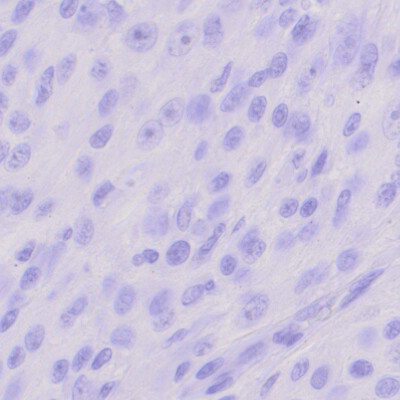

In [ ]:
slide.read_region(location=(30000,30000),size=(400,400), level=1)

In [2]:
slide = slideio.open_slide('../exact/images/exact_1_1/MCT_A5412-15_f_VMU_VMU_ZAZ1_HE_F2.czi')
scene=slide.get_scene(0)

In [12]:
scene

File Path: ../../../STS_T6396_21_2_pHH3.vsi
Name: 40x_BF_01
Rect: 0,0,85442,76566
Number of Channels: 3
Channel 0 data type: DT_Byte
Channel 1 data type: DT_Byte
Channel 2 data type: DT_Byte
Number of Z-Slices: 1
Number of Time Frames: 1
Z-Slice Resolution: 0
Time Frame Resolution: 0
Magnification: 40
Number of Auxiliary Images: 1
Number of Zoom Levels: 9

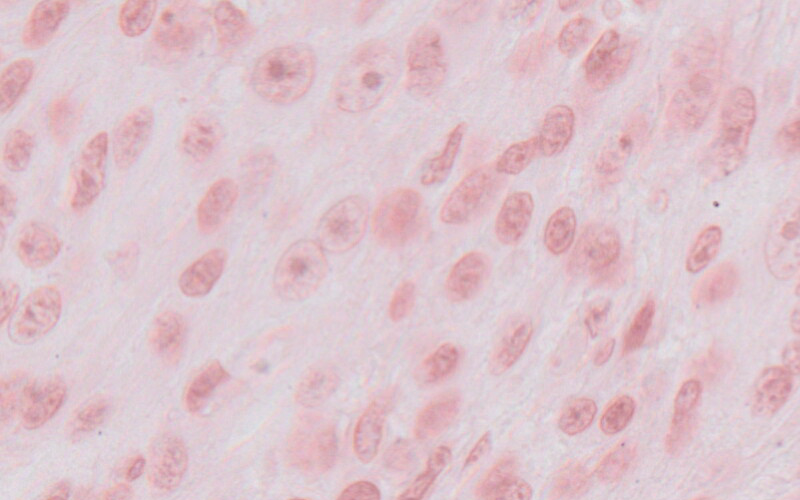

In [17]:
from PIL import Image
Image.fromarray(scene.read_block(rect=(30000,30000,800,500), size=(800,500))[:,:,::-1])

In [4]:
import os

os.path.splitext('../../../Downloads/MCT_A5412-15_f_VMU_VMU_ZAZ1_HE_F2.czi')[1]

'.czi'

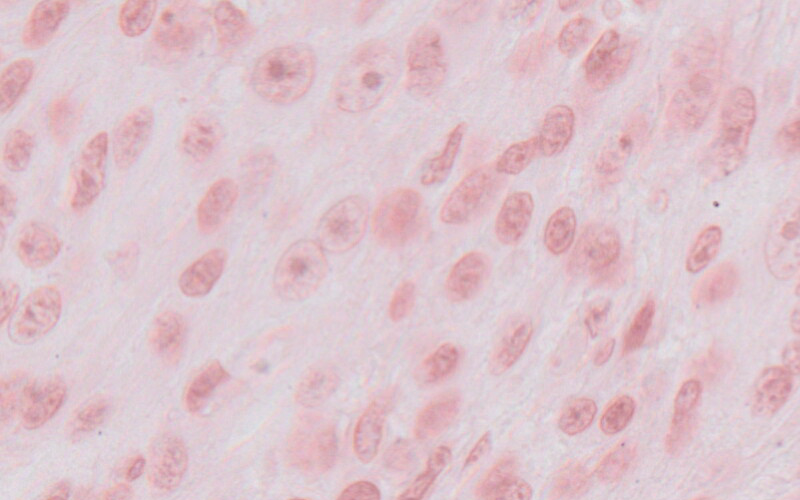

In [13]:
from PIL import Image
Image.fromarray(scene.read_block(rect=(30000,30000,800,500), size=(800,500))[:,:,::-1])

In [6]:
sl = SlideIOSlide('./images/exact_1_1/MCT_A5412-15_f_VMU_VMU_ZAZ1_HE_F2.czi')

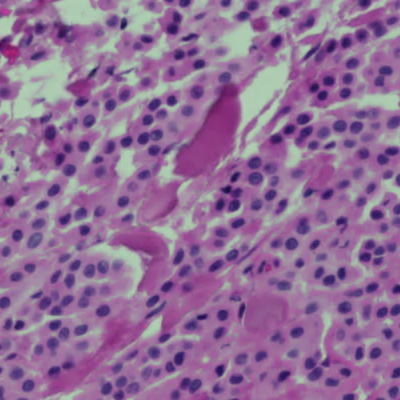

In [7]:
sl.read_region(location=(30000,30000),size=(400,400), level=2)

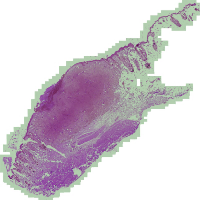

In [8]:
sl.get_thumbnail(size=(200,200))

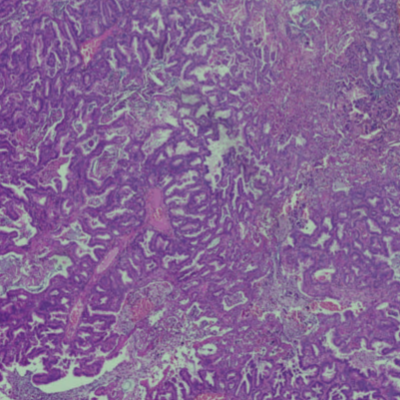

In [9]:
from util.slide_server import getSlideHandler
slh = getSlideHandler('/Users/marcaubreville/code/Exact/exact/images/exact_1_1/LUC_G5864-17_c_VMU_VMU_ZAZ1_HE_F2.czi')
#slh = getSlideHandler('./images/exact_1_1/Human01_All_stack.vsi')

slh.read_region(location=(30000,30000),size=(400,400), level=6)

In [6]:
import slideio
from concurrent.futures import ThreadPoolExecutor
import random

sl = slideio.open_slide('../../slideio/test/vsi/STS_G6889_11_1_pHH3/STS_G6889_11_1_pHH3.vsi')
#sc = sl.slide.get_scene(0)

sc = sl.get_scene(0)

# Get scene dimensions
scene_width, scene_height = sc.rect[2], sc.rect[3]
block_size = (1024, 1024)

def read_random_block():
    # Generate random coordinates
    x = random.randint(0, scene_width - block_size[0])
    y = random.randint(0, scene_height - block_size[1])
    rect = (x, y, block_size[0], block_size[1])

    # Read the block and return the coordinates for debugging
    block = sc.read_block(rect=rect, size=block_size)
    print(f"Read block at {rect}")
    return block

# Number of threads / blocks to read
num_threads = 4

# Run the block reading in threads
with ThreadPoolExecutor(max_workers=num_threads) as executor:
    blocks = list(executor.map(lambda _: read_random_block(), range(num_threads)))

: 

In [4]:

sc.read_block(rect=(0,0,1024,1024), size=(1024,1024))

array([[[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       ...,

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]]

In [16]:
slh.read_region(location=(15000,15000), size=(512,512), level=4)

ValueError: cannot convert float NaN to integer

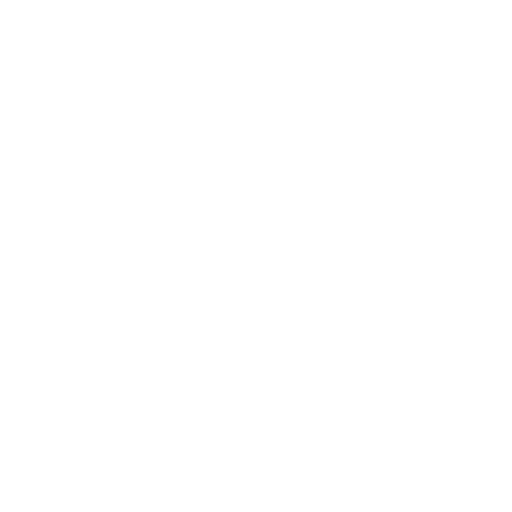

In [8]:
slh.read_region(location=(15000,15000), size=(512,512), level=1, frame=20)

In [5]:
slh.frame_descriptors

['0.00 µ',
 '0.37 µ',
 '0.74 µ',
 '1.11 µ',
 '1.48 µ',
 '1.85 µ',
 '2.22 µ',
 '2.59 µ',
 '2.96 µ',
 '3.33 µ',
 '3.70 µ',
 '4.07 µ',
 '4.44 µ',
 '4.81 µ',
 '5.18 µ',
 '5.55 µ',
 '5.92 µ',
 '6.29 µ',
 '6.66 µ',
 '7.03 µ',
 '7.40 µ',
 '7.77 µ',
 '8.14 µ',
 '8.51 µ',
 '8.88 µ',
 '9.25 µ',
 '9.62 µ']

In [17]:
slh.level_dimensions

[[280829, 167529],
 [140415, 83765],
 [70207, 41882],
 [35104, 20941],
 [17552, 10471],
 [8776, 5235],
 [4388, 2618],
 [2194, 1309],
 [1097, 654],
 [548, 327]]

In [55]:
from util.slide_server import getSlideHandler
slh = getSlideHandler('/Users/marcaubreville/code/Exact/exact/images/exact_1_1/LUC_G5864-17_c_VMU_VMU_ZAZ1_HE_F2.czi')
#slh = getSlideHandler('./images/exact_1_1/Human01_All_stack.vsi')

slh.read_region(location=(30000,30000),size=(400,400), level=6)

from openslide.deepzoom import DeepZoomGenerator
dzg = DeepZoomGenerator(slh)

Returning  (400, 400, 4)


In [57]:
tile = dzg.get_tile(10,(0,0))

slide level:  9 _z_t_downsample 254 _z_dimensions ((1, 1), (2, 1), (3, 2), (5, 3), (9, 6), (18, 11), (35, 21), (69, 41), (138, 82), (275, 164), (549, 328), (1097, 655), (2194, 1309), (4388, 2618), (8776, 5236), (17552, 10471), (35104, 20942), (70208, 41883), (140415, 83765), [280829, 167529])
l size (255, 255) z size (255, 255)
Returning  (255, 255, 4)
(255, 255) #000000
(255, 255)
(255, 255)
(255, 255) (255, 255, 3)


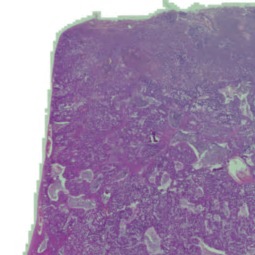

In [58]:
tile

In [59]:
slh = getSlideHandler('../../slideio/test/vsi/STS_G6889_11_1_pHH3/STS_G6889_11_1_pHH3.vsi')
dzg = DeepZoomGenerator(slh)

TIFFReadDirectory: Warning, Unknown field with tag 33560 (0x8318) encountered.
TIFFReadDirectory: Warning, Unknown field with tag 33560 (0x8318) encountered.
TIFFReadDirectory: Warning, Unknown field with tag 33560 (0x8318) encountered.


In [60]:
tile = dzg.get_tile(10,(0,0))

slide level:  8 _z_t_downsample 254 _z_dimensions ((1, 1), (2, 2), (3, 3), (6, 5), (11, 10), (21, 19), (41, 37), (81, 74), (161, 148), (321, 295), (642, 589), (1284, 1178), (2567, 2356), (5134, 4711), (10267, 9422), (20534, 18843), (41067, 37685), (82134, 75370), [164267, 150739])
l size (255, 255) z size (255, 255)
Returning  (255, 255, 4)
(255, 255) #000000
(255, 255)
(255, 255)
(255, 255) (255, 255, 3)


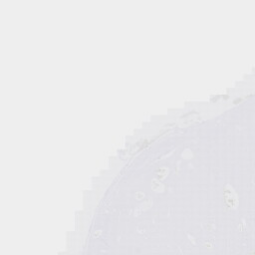

In [61]:
tile

In [62]:
slh = getSlideHandler('./images/exact_1_1/MCT_G5149-16_f_VMU_VMU_3DHP250_HE_F1.mrxs')
dzg = DeepZoomGenerator(slh)

In [63]:
tile = dzg.get_tile(10,(0,0))

slide level:  8 _z_t_downsample 254 _z_dimensions ((1, 1), (1, 2), (2, 4), (3, 7), (6, 13), (12, 26), (23, 51), (45, 101), (90, 202), (179, 404), (357, 807), (714, 1614), (1428, 3227), (2856, 6454), (5712, 12908), (11424, 25815), (22848, 51630), (45695, 103260), (91390, 206520), (182779, 413039))
l size (510, 510) z size (255, 255)
(510, 510) #FFFFFF
(510, 510)
(255, 255)
(255, 255) (255, 255, 3)


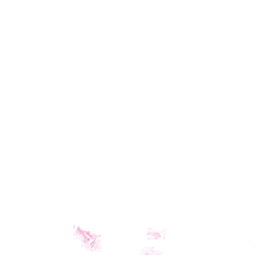

In [64]:
tile

In [1]:
%reload_ext autoreload
%autoreload 2
%matplotlib inline

from util.slide_server import getSlideHandler

source_image = '/Users/marcaubreville/code/Exact/exact/images/exact_1_1/STS_A5287_18_1_pHH3.vsi'
target_image = '/Users/marcaubreville/code/Exact/exact/images/exact_1_1/STS_A5287_18_1_HE.vsi'

source_image = getSlideHandler(source_image)
target_image = getSlideHandler(target_image)


Magic number: ['0x49', '0x49', '0x2a', '0x0']
Magic number: ['0x49', '0x49', '0x2a', '0x0']


TIFFReadDirectory: Warning, Unknown field with tag 33560 (0x8318) encountered.
TIFFReadDirectory: Warning, Unknown field with tag 33560 (0x8318) encountered.
TIFFReadDirectory: Warning, Unknown field with tag 33560 (0x8318) encountered.
TIFFReadDirectory: Warning, Unknown field with tag 33560 (0x8318) encountered.
TIFFReadDirectory: Warning, Unknown field with tag 33560 (0x8318) encountered.
TIFFReadDirectory: Warning, Unknown field with tag 33560 (0x8318) encountered.


In [2]:
source_image, target_image

(<util.slideio.SlideIOSlide at 0x128031750>,
 OpenSlideWrapper('/Users/marcaubreville/code/Exact/exact/images/exact_1_1/LUC_G5864-17_c_VMU_VMU_DEHS60_HE_F2 - 2025-02-10 10.33.ndpi'))

In [35]:
import qt_wsi_reg.registration_tree as registration
import pickle

parameters = {
                # feature extractor parameters
                "point_extractor": "sift",  #orb , sift
                "maxFeatures": 2048, 
                "crossCheck": False, 
                "flann": False,
                "ratio": 0.7, 
                "use_gray": False,

                # QTree parameter 
                "homography": True,
                "filter_outliner": False,
                "debug": True,
                "target_depth": 2,
                "run_async": True,
                "num_workers": 2,
                "thumbnail_size": (1024, 1024)
            }



qtree = registration.RegistrationQuadTree(source_slide=source_image, image_normalization_source='clahe', image_normalization_target='', target_slide=target_image, **parameters)
registration_error = qtree.mean_reg_error
print('Registration error: ', registration_error)
runtime = qtree.run_time
transformation_matrix = {"t_00": qtree.get_homography[0][0], "t_01": qtree.get_homography[0][1], "t_02": qtree.get_homography[0][2], 
                                "t_10": qtree.get_homography[1][0], "t_11": qtree.get_homography[1][1], "t_12": qtree.get_homography[1][2], 
                                "t_20": qtree.get_homography[2][0], "t_21": qtree.get_homography[2][1], "t_22": qtree.get_homography[2][2]}

content = pickle.dumps(qtree)


len kpsA: 128
len kpsB: 1045
len kpsA: 328
len kpsB: 2044
len kpsA: 411
len kpsB: 2069
len kpsA: 450
len kpsB: 870
len kpsA: 1641
len kpsB: 3496
len kpsA: 919
len kpsB: 1600
len kpsA: 1005
len kpsB: 3107
len kpsA: 2167
len kpsB: 3365
len kpsA: 1382
len kpsB: 5389
len kpsA: 1664
len kpsB: 4928
len kpsA: 1913
len kpsB: 3430
len kpsA: 127
len kpsB: 1343
len kpsA: 57
len kpsB: 1077
len kpsA: 629
len kpsB: 4767
len kpsA: 2220
len kpsB: 4206
len kpsA: 396
len kpsB: 1490
len kpsA: 720
len kpsB: 4688
len kpsA: 910
len kpsB: 1919
len kpsA: 164
len kpsB: 1159
len kpsA: 10
len kpsB: 89
len kpsA: 0
len kpsB: 13
Registration error:  380.10688069583335


In [16]:
qtree.ptsB

array([[ 7303.30024266, 45173.59885297]])